In [1]:
import pandas as pd
import numpy as np

# 1) Load counts with genes as index, cells as columns
counts = pd.read_csv("PatchSeqExpression/GSE163764_m1_patchseq_exon_counts.csv", index_col=0)
# counts: genes × cells

# 2) Transpose to cells × genes (what your code expects)
expr = counts.T  # cells × genes

# 3) Library-size normalize → logCPM
libsize = expr.sum(axis=1)
cpm = expr.div(libsize, axis=0) * 1e6
log_cpm = np.log1p(cpm)

# 4) Plasticity genes
genes_of_interest = [
    "Fos","Fosb","Junb","Egr1","Egr2","Npas4","Arc","Homer1a",
    "Nr4a1","Nr4a2","Bdnf","Nptx2","Syt4","Camk2g",
    "Rgs4","Dusp1","Atf3","Crem","Gadd45b","Gadd45g","Prkcz"
]

present = [g for g in genes_of_interest if g in log_cpm.columns]
print("Present genes:", present)

# 5) Compute z-scores gene-wise and the plasticity score
X = log_cpm[present]
Xz = (X - X.mean(axis=0)) / X.std(axis=0)
plasticity_score = Xz.mean(axis=1)

# Attach to your obs (or just keep as a Series for now)
# adata.obs["plasticity_score"] = plasticity_score.reindex(adata.obs_names)


Present genes: ['Fos', 'Fosb', 'Junb', 'Egr1', 'Egr2', 'Npas4', 'Arc', 'Nr4a1', 'Nr4a2', 'Bdnf', 'Nptx2', 'Syt4', 'Camk2g', 'Rgs4', 'Dusp1', 'Atf3', 'Crem', 'Gadd45b', 'Gadd45g', 'Prkcz']


In [2]:
plasticity_score.describe()

count    1.329000e+03
mean     4.277157e-17
std      5.446066e-01
min     -1.365027e+00
25%     -3.569973e-01
50%     -3.320849e-02
75%      3.478808e-01
max      1.366444e+00
dtype: float64

In [3]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import re
from pathlib import Path

COUNTS = Path("PatchSeqExpression/GSE163764_m1_patchseq_exon_counts.csv")
SERIES = Path("PatchSeqExpression/GSE163764_series_matrix.txt")

# counts file: first column = gene symbols, remaining columns = cell IDs like "20180420_sample_2"
counts_gxc = pd.read_csv(COUNTS, index_col=0)          # genes × cells
expr = counts_gxc.T                                   # cells × genes

# make an AnnData from the full matrix (we’ll use this for PCA/UMAP)
adata = ad.AnnData(X=expr.values, obs=pd.DataFrame(index=expr.index),
                   var=pd.DataFrame(index=expr.columns))


Present genes: ['Fos', 'Fosb', 'Junb', 'Egr1', 'Egr2', 'Npas4', 'Arc', 'Nr4a1', 'Nr4a2', 'Bdnf', 'Nptx2', 'Syt4', 'Camk2g', 'Rgs4', 'Dusp1', 'Atf3', 'Crem', 'Gadd45b', 'Gadd45g', 'Prkcz']


/home/peter/.local/lib/python3.10/site-packages/legacy_api_wrap/__init__.py:82: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)
/home/peter/.local/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


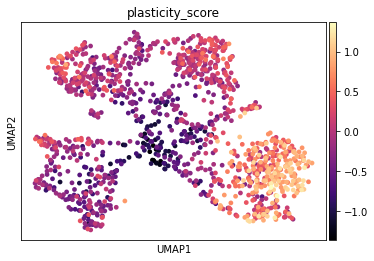

In [4]:
import pandas as pd, numpy as np, scanpy as sc, anndata as ad

COUNTS = "PatchSeqExpression/GSE163764_m1_patchseq_exon_counts.csv"

# 1) Load counts (genes×cells) → cells×genes
counts_gxc = pd.read_csv(COUNTS, index_col=0)
expr = counts_gxc.T  # cells × genes

# 2) AnnData + logCPM layer
adata = ad.AnnData(expr.values, obs=pd.DataFrame(index=expr.index),
                   var=pd.DataFrame(index=expr.columns))
libsize = adata.X.sum(axis=1)
if hasattr(libsize, "A1"): libsize = libsize.A1
cpm = adata.X / libsize[:, None] * 1e6
adata.layers["logcpm"] = np.log1p(cpm)

# 3) Plasticity score (IEG set)
genes_plastic = ["Fos","Fosb","Junb","Egr1","Egr2","Npas4","Arc","Homer1a",
                 "Nr4a1","Nr4a2","Bdnf","Nptx2","Syt4","Camk2g",
                 "Rgs4","Dusp1","Atf3","Crem","Gadd45b","Gadd45g","Prkcz"]
present = [g for g in genes_plastic if g in adata.var_names]
adata_pl = adata[:, present].copy()
X = np.asarray(adata_pl.layers["logcpm"])
Xz = (X - X.mean(axis=0)) / X.std(axis=0)
adata.obs["plasticity_score"] = Xz.mean(axis=1)
print("Present genes:", present)

# 4) Embed ALL CELLS (HVGs from logCPM) and color by plasticity
adata_use = adata.copy()
adata_use.X = adata.layers["logcpm"]
sc.pp.highly_variable_genes(adata_use, n_top_genes=3000, flavor="seurat_v3")
adata_use = adata_use[:, adata_use.var["highly_variable"]].copy()
sc.pp.scale(adata_use, zero_center=False)
sc.tl.pca(adata_use, n_comps=50, svd_solver="auto")
sc.pp.neighbors(adata_use, n_neighbors=15, n_pcs=50)
sc.tl.umap(adata_use)
adata_use.obs["plasticity_score"] = adata.obs["plasticity_score"]

sc.pl.umap(adata_use, color=["plasticity_score"], cmap="magma")

# 5) Save outputs
adata_use.write_h5ad("Outputs/GSE163764_allcells_logcpm_hvg_umap.h5ad", compression="lzf")
adata.obs[["plasticity_score"]].to_csv("Outputs/GSE163764_plasticity_scores.csv")


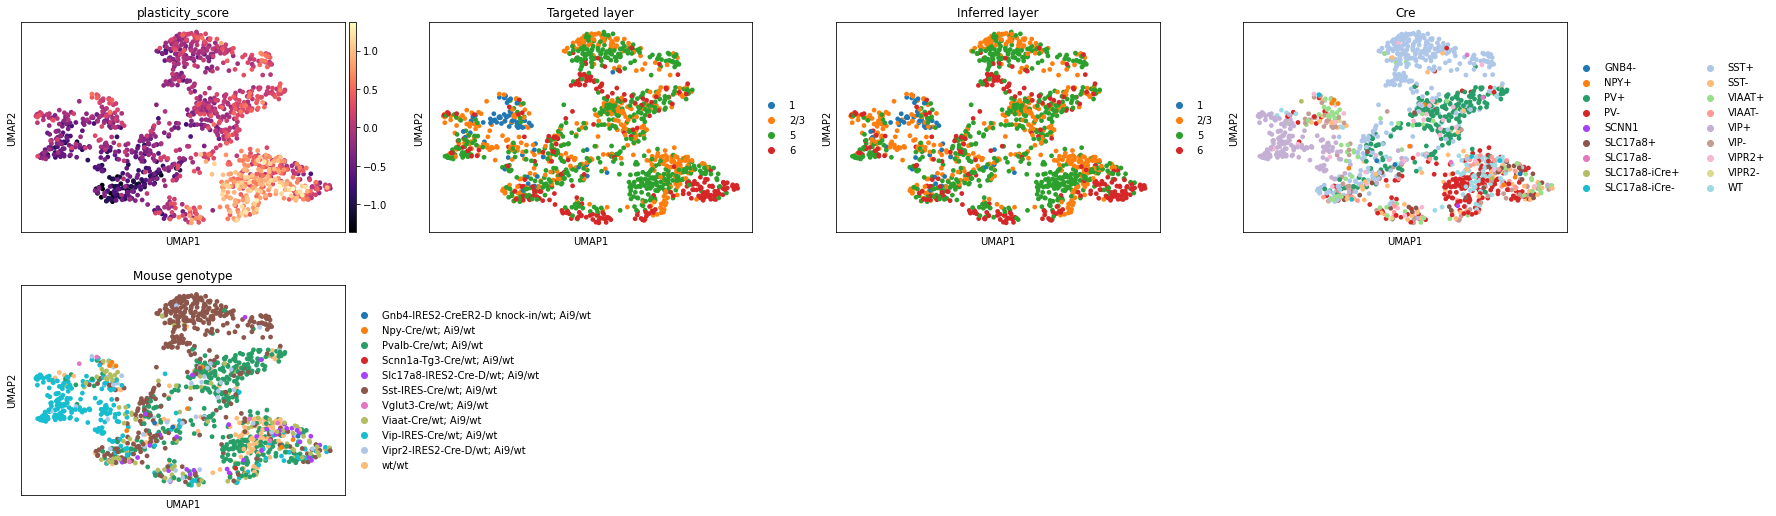

In [5]:
import pandas as pd
import scanpy as sc

# 1) Load metadata (TSV!)
meta = pd.read_csv("PatchSeqExpression/m1_patchseq_meta_data.csv", sep="\t")   # <-- key fix
meta = meta.rename(columns={"Cell":"cell_key"}).set_index("cell_key")

# 2) Join onto your AnnData (adata.obs.index are the cell ids from counts)
adata.obs = adata.obs.join(meta, how="left")

# NOW build adata_use from adata (will carry obs columns)
adata_use = adata.copy()
adata_use.X = adata.layers["logcpm"]

sc.pp.highly_variable_genes(adata_use, n_top_genes=3000, flavor="seurat")  # or seurat_v3 if using counts
adata_use = adata_use[:, adata_use.var["highly_variable"]].copy()
sc.pp.scale(adata_use, zero_center=False)
sc.tl.pca(adata_use, n_comps=50)
sc.pp.neighbors(adata_use, n_pcs=50)
sc.tl.umap(adata_use)

sc.pl.umap(adata_use, color=["plasticity_score","Targeted layer","Inferred layer","Cre","Mouse genotype"], cmap="magma")


In [14]:
meta.columns

Index(['Number', 'Slice', 'Date', 'Sample', 'Mouse', 'Mouse date of birth',
       'Mouse age', 'Mouse gender', 'Mouse genotype', 'Targeted layer',
       'Inferred layer', 'Cre', 'Exon reads', 'Intron reads',
       'Intergenic reads', 'Sequencing batch', 'Number of genes detected',
       'RNA family', 'RNA type', 'RNA type confidence', 'RNA type top-3',
       'ALM/VISp top-3', 'Length (bp)', 'Yield (pg/µl)', 'User',
       'Hold Time (min)', 'Soma depth (µm)', 'Soma depth (4x)',
       'Cortical thickness (4x)', 'Cortical thickness (µm)', 'Traced',
       'Exclusion reasons'],
      dtype='object')

In [11]:
is_L5 = (
    adata_use.obs.get("Inferred layer", "").astype(str).str.contains(r"\b5\b", na=False)
    | adata_use.obs.get("Targeted layer", "").astype(str).str.contains(r"\b5\b", na=False)
)

pt_cre_pat = r"(fezf2|sim1|bcl11b|ctip2|tbr1|glt25d2)"
is_PT = adata_use.obs.get("Cre", "").astype(str).str.contains(pt_cre_pat, case=False, na=False)

adata_l5pt = adata_use[is_L5 & is_PT].copy()
sc.pp.scale(adata_l5pt, zero_center=False)
sc.tl.pca(adata_l5pt, n_comps=30); sc.pp.neighbors(adata_l5pt, n_pcs=30); sc.tl.umap(adata_l5pt)
sc.pl.umap(adata_l5pt, color=["plasticity_score","Cre","Targeted layer"], cmap="magma")


/tmp/ipykernel_26699/1333050068.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  is_PT = adata_use.obs.get("Cre", "").astype(str).str.contains(pt_cre_pat, case=False, na=False)
/home/peter/.local/lib/python3.10/site-packages/scanpy/preprocessing/_utils.py:31: RuntimeWarning: Mean of empty slice.
  return x.mean(axis=axis, dtype=dtype)
/home/peter/.local/lib/python3.10/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


ValueError: Found array with 0 sample(s) (shape=(0, 3000)) while a minimum of 1 is required by PCA.

/tmp/ipykernel_26699/1370902370.py:34: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  m_PT = adata_use.obs.get("Cre", "").astype(str).str.contains(pt_cre_pat, case=False, na=False)


L5 cells: 650


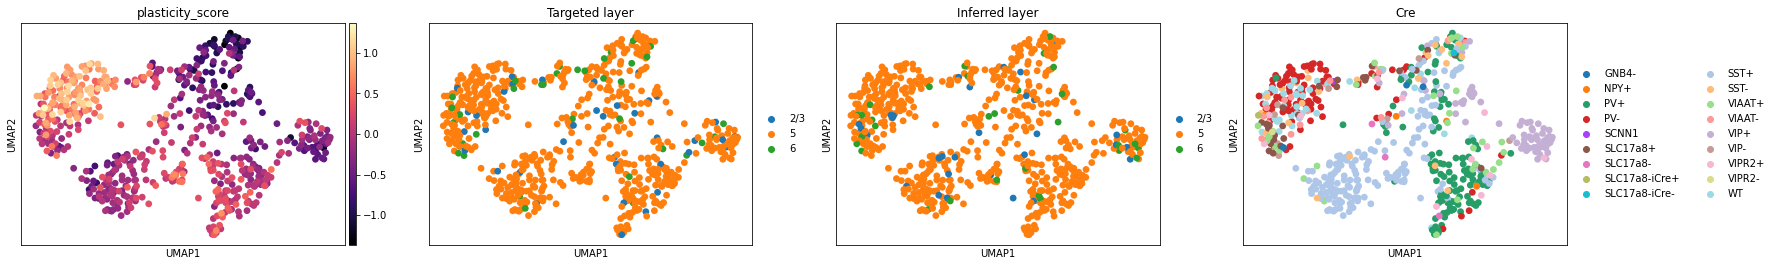

In [13]:
import pandas as pd
import numpy as np
import scanpy as sc

# --- 0) Re-attach metadata to the base AnnData (adata) ---
meta = pd.read_csv("PatchSeqExpression/m1_patchseq_meta_data.csv", sep="\t") \
         .rename(columns={"Cell":"cell_key"}).set_index("cell_key")

# join only new columns to avoid overlap errors
new_cols = [c for c in meta.columns if c not in adata.obs.columns]
adata.obs = adata.obs.join(meta[new_cols], how="left")

# make sure the UMAP object (adata_use) carries obs columns
for c in ["Targeted layer","Inferred layer","Cre","Mouse genotype","plasticity_score"]:
    if c in adata.obs.columns:
        adata_use.obs[c] = adata.obs.loc[adata_use.obs_names, c]

# --- 1) Build a robust L5 mask (numeric or string) ---
def is_layer5(series):
    s = series.copy()
    # try numeric equality
    num = pd.to_numeric(s, errors="coerce")
    m_num = (num == 5)
    # string contains whole-word '5'
    s = s.astype(str)
    m_str = s.str.contains(r"\b5\b", na=False)
    return m_num.fillna(False) | m_str

m_L5 = is_layer5(adata_use.obs.get("Inferred layer", np.nan)) \
    |  is_layer5(adata_use.obs.get("Targeted layer", np.nan))

# --- 2) (Optional) PT-leaning Cre mask ---
pt_cre_pat = r"(fezf2|sim1|bcl11b|ctip2|tbr1|glt25d2)"
m_PT = adata_use.obs.get("Cre", "").astype(str).str.contains(pt_cre_pat, case=False, na=False)

# Choose your subset:
#   L5-only:
adata_l5 = adata_use[m_L5].copy()
#   L5-PT (comment out if you just want L5):
# adata_l5 = adata_use[m_L5 & m_PT].copy()

print("L5 cells:", adata_l5.n_obs)

# --- 3) Re-embed the subset (recommended) ---
sc.pp.scale(adata_l5, zero_center=False)
sc.tl.pca(adata_l5, n_comps=30)
sc.pp.neighbors(adata_l5, n_pcs=30)
sc.tl.umap(adata_l5)

sc.pl.umap(adata_l5, color=["plasticity_score","Targeted layer","Inferred layer","Cre"], cmap="magma")


Unique Targeted layer: ['1', '2/3', '5', '6']
Unique Inferred layer: ['1', '2/3', '5', '6']
N target L5: 576  | N inferred L5: 586  | N union L5: 650  | N target-only: 64  | N inferred-only: 74
L5 cells (Targeted layer==5): 576


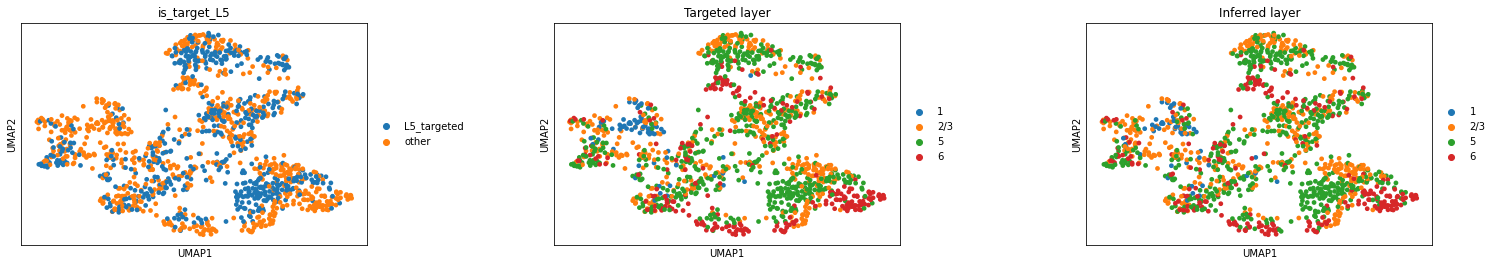

In [15]:
import pandas as pd
import numpy as np
import scanpy as sc

# 0) Quick audit of layer fields
print("Unique Targeted layer:", sorted(adata_use.obs["Targeted layer"].astype(str).unique()))
print("Unique Inferred layer:", sorted(adata_use.obs["Inferred layer"].astype(str).unique()))

# 1) Exact “Targeted layer == 5” mask (robust to numeric/string)
def is_layer5(series):
    s = pd.Series(series, copy=False)
    num = pd.to_numeric(s, errors="coerce")
    m_num = (num == 5)
    m_str = s.astype(str).str.contains(r"\b5\b", na=False)
    return m_num.fillna(False) | m_str

m_target5  = is_layer5(adata_use.obs.get("Targeted layer"))
m_infer5   = is_layer5(adata_use.obs.get("Inferred layer"))
m_L5_union = m_target5 | m_infer5

print(
    f"N target L5: {m_target5.sum()}  | "
    f"N inferred L5: {m_infer5.sum()}  | "
    f"N union L5: {m_L5_union.sum()}  | "
    f"N target-only: {(m_target5 & ~m_infer5).sum()}  | "
    f"N inferred-only: {(~m_target5 & m_infer5).sum()}"
)

# 2) Make the subset using **only targeted layer==5** (as you asked)
adata_l5 = adata_use[m_target5].copy()
print("L5 cells (Targeted layer==5):", adata_l5.n_obs)

# 3) Visual sanity checks
adata_use.obs["is_target_L5"] = np.where(m_target5, "L5_targeted", "other")
sc.pl.umap(adata_use, color=["is_target_L5","Targeted layer","Inferred layer"], wspace=0.4)


Unique Targeted layer: ['1', '2/3', '5', '6']
Unique Inferred layer: ['1', '2/3', '5', '6']
N target L5: 576  | N inferred L5: 586  | N union L5: 650  | N target-only: 64  | N inferred-only: 74
L5 cells (Targeted layer==5): 576


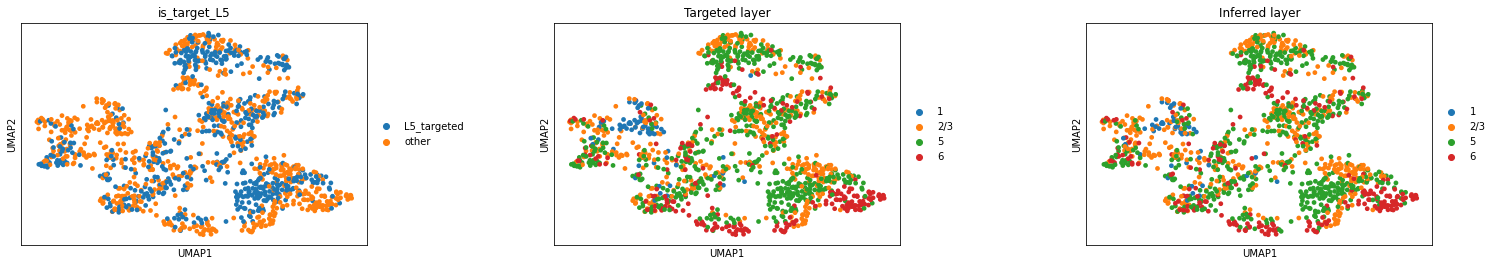

In [16]:
import pandas as pd
import numpy as np
import scanpy as sc

# 0) Quick audit of layer fields
print("Unique Targeted layer:", sorted(adata_use.obs["Targeted layer"].astype(str).unique()))
print("Unique Inferred layer:", sorted(adata_use.obs["Inferred layer"].astype(str).unique()))

# 1) Exact “Targeted layer == 5” mask (robust to numeric/string)
def is_layer5(series):
    s = pd.Series(series, copy=False)
    num = pd.to_numeric(s, errors="coerce")
    m_num = (num == 5)
    m_str = s.astype(str).str.contains(r"\b5\b", na=False)
    return m_num.fillna(False) | m_str

m_target5  = is_layer5(adata_use.obs.get("Targeted layer"))
m_infer5   = is_layer5(adata_use.obs.get("Inferred layer"))
m_L5_union = m_target5 | m_infer5

print(
    f"N target L5: {m_target5.sum()}  | "
    f"N inferred L5: {m_infer5.sum()}  | "
    f"N union L5: {m_L5_union.sum()}  | "
    f"N target-only: {(m_target5 & ~m_infer5).sum()}  | "
    f"N inferred-only: {(~m_target5 & m_infer5).sum()}"
)

# 2) Make the subset using **only targeted layer==5** (as you asked)
adata_l5 = adata_use[m_target5].copy()
print("L5 cells (Targeted layer==5):", adata_l5.n_obs)

# 3) Visual sanity checks
adata_use.obs["is_target_L5"] = np.where(m_target5, "L5_targeted", "other")
sc.pl.umap(adata_use, color=["is_target_L5","Targeted layer","Inferred layer"], wspace=0.4)


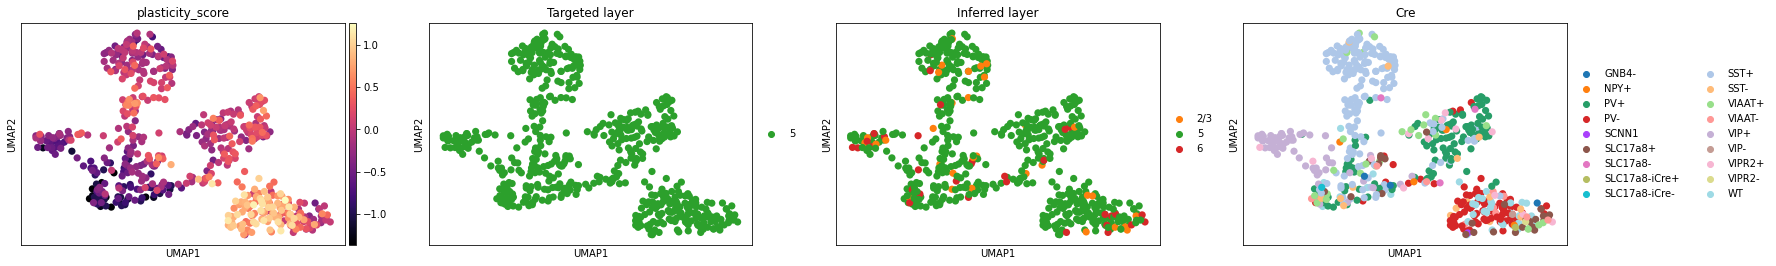

In [24]:
sc.pp.scale(adata_l5, zero_center=False)
sc.tl.pca(adata_l5, n_comps=30)
sc.pp.neighbors(adata_l5, n_pcs=30)
sc.tl.umap(adata_l5)
sc.pl.umap(adata_l5, color=["plasticity_score","Targeted layer","Inferred layer","Cre"], cmap="magma")


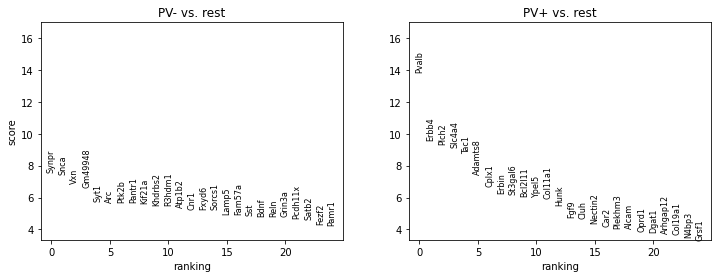

In [27]:
import pandas as pd
import scanpy as sc

# make a 2-level label from Cre
pv_map = {
    "PV+": "PV+",
    "PV-": "PV-",
    # everything else (VIP+, SST+, etc.) -> PV- if you want a broad excitatory+non-PV comparison
}
adata_l5.obs["PV_status"] = adata_l5.obs["Cre"].map(pv_map).fillna("PV-").astype("category")

# (optional) drop rare groups
min_cells = 5
keep = adata_l5.obs["PV_status"].value_counts()
valid_groups = keep[keep >= min_cells].index.tolist()

sc.tl.rank_genes_groups(adata_l5, groupby="PV_status",
                        groups=valid_groups, method="wilcoxon")
sc.pl.rank_genes_groups(adata_l5, groups=valid_groups, n_genes=25)



In [33]:
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

def gene_vec(adata, gene, default=np.nan):
    if gene not in adata.var_names:
        return np.full(adata.n_obs, default, dtype=float)
    X = adata[:, gene].X
    if hasattr(X, "A1"): X = X.A1
    return np.asarray(X, dtype=float)

def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    gt = (a[:,None] > b).sum(); lt = (a[:,None] < b).sum()
    return (gt - lt) / (a.size * b.size)
adata = adata_l5.copy()  # your L5 subset already

# Excitatory gate: high Slc17a7 & low Gad1/2 (fallback to Cre if genes missing)
slc = gene_vec(adata, "Slc17a7", 0.0)
gad1 = gene_vec(adata, "Gad1",   0.0)
gad2 = gene_vec(adata, "Gad2",   0.0)

# Thresholds that work even with skewed data
slc_thr = np.nanpercentile(slc, 50)         # median
gad_thr = np.nanpercentile(np.r_[gad1,gad2], 25)  # lower quartile

is_excit_marker = (slc >= slc_thr) & (gad1 <= gad_thr) & (gad2 <= gad_thr)

# Optional fallback using Cre: treat PV+ as inhibitory
cre = adata.obs.get("Cre", pd.Series(index=adata.obs_names, dtype=object)).astype(str)
is_excit_cre = cre != "PV+"

is_excit = is_excit_marker | is_excit_cre

# Layer-5 gate (handles '5', 'L5', 'layer 5')
layer_col = "Inferred layer" if "Inferred layer" in adata.obs else "Targeted layer"
is_L5 = adata.obs[layer_col].astype(str).str.contains(r"\b5\b", case=False, regex=True)

adata_excL5 = adata[is_excit & is_L5].copy()
print("L5 excitatory cells:", adata_excL5.n_obs)


ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 1 dimension(s) and the array at index 1 has 2 dimension(s)

In [32]:
import numpy as np, pandas as pd

# ---- 0) Robust gene vector getter ----
def get_gene_vec(adata, gene_symbol, default_val=0.0):
    """
    Return a 1D float vector for the requested gene, resolving:
    - var_names case/alias (e.g., 'SLC17A7' vs 'Slc17a7')
    - gene symbol columns in .var (e.g., 'gene_symbol','symbols','feature_name')
    - .raw var_names if counts were stashed there
    If nothing matches, returns a constant vector (default_val).
    """
    def _resolve_one(_adata):
        # 1) direct match in var_names (case-insensitive)
        lower_map = {k.lower(): k for k in list(_adata.var_names)}
        hit = lower_map.get(gene_symbol.lower())
        if hit is not None:
            X = _adata[:, hit].X
            return X.A1 if hasattr(X, "A1") else np.asarray(X).ravel()

        # 2) search symbol-ish columns in .var
        cand_cols = [c for c in _adata.var.columns
                     if str(c).lower() in {"gene_symbol","gene_symbols","symbol","symbols","feature_name","gene","name"}]
        for c in cand_cols:
            # map symbol -> var index
            series = _adata.var[c].astype(str).str.lower()
            idx = np.where(series.values == gene_symbol.lower())[0]
            if idx.size:
                j = int(idx[0])
                X = _adata.X[:, j] if _adata.is_view else _adata.X[:, j]
                # safer slice:
                X = _adata[:, _adata.var.index[j]].X
                return X.A1 if hasattr(X, "A1") else np.asarray(X).ravel()

        # 3) fuzzy contains search (last resort)
        for name in list(_adata.var_names):
            if gene_symbol.lower() in str(name).lower():
                X = _adata[:, name].X
                return X.A1 if hasattr(X, "A1") else np.asarray(X).ravel()
        return None

    vec = _resolve_one(adata)
    if vec is None and adata.raw is not None:
        try:
            vec = _resolve_one(adata.raw.to_adata())
        except Exception:
            vec = None
    if vec is None:
        # fall back to a constant vector so downstream code still runs
        vec = np.full(adata.n_obs, float(default_val))
    return vec.astype(float)

# ---- 1) Use multiple excitatory/inhibitory markers (any that exist) ----
slc17a7 = get_gene_vec(adata_l5, "Slc17a7")     # VGlut1 (excitatory cortex)
slc17a6 = get_gene_vec(adata_l5, "Slc17a6")     # VGlut2 (subcortical proj; sometimes present)
slc17a8 = get_gene_vec(adata_l5, "Slc17a8")     # VGlut3 (rare, but harmless)
gad1     = get_gene_vec(adata_l5, "Gad1")       # GABA
gad2     = get_gene_vec(adata_l5, "Gad2")       # GABA

exc_signal = np.nanmax(np.c_[slc17a7, slc17a6, slc17a8], axis=1)  # use whatever exists
inh_signal = np.nanmax(np.c_[gad1, gad2], axis=1)

# adaptive thresholds (robust to scale)
exc_thr = np.nanpercentile(exc_signal, 50)
inh_thr = np.nanpercentile(inh_signal, 25)

is_excit = (exc_signal >= exc_thr) & (inh_signal <= inh_thr)

# ---- 2) Layer-5 gate and projection classes (if available) ----dd
layer_col = "Inferred layer" if "Inferred layer" in adata_l5.obs else "Targeted layer"
is_L5 = adata_l5.obs[layer_col].astype(str).str.contains(r"\b5\b", case=False, regex=True)

if "proj_class" in adata_l5.obs:
    is_proj = adata_l5.obs["proj_class"].isin(["IT","PT","CT"])
else:
    is_proj = pd.Series(True, index=adata_l5.obs_names)

mask_exc_L5 = (is_excit & is_L5.values & is_proj.values)
adata_excL5 = adata_l5[mask_exc_L5].copy()
print("Selected L5 excitatory cells:", adata_excL5.n_obs)
# show a few column candidates that exist in your .var
print([c for c in adata_l5.var.columns if str(c).lower() in
       {"gene_symbol","gene_symbols","symbol","symbols","feature_name","gene","name"}][:5])

# list a few var_names that look like SLC17A7
print([v for v in adata_l5.var_names if "slc17a7".lower() in str(v).lower()][:10])


Selected L5 excitatory cells: 88
[]
[]


In [19]:
# 1) Build a projection-class label (IT/PT/CT)
if "RNA type" in adata_l5.obs.columns:
    proj = adata_l5.obs["RNA type"].astype(str)
else:
    proj = adata_l5.obs["RNA type top-3"].astype(str)

def pick_class(s):
    s = s.upper()
    if "PT" in s: return "PT"
    if "CT" in s: return "CT"
    if "IT" in s: return "IT"
    return np.nan

adata_l5.obs["proj_class"] = proj.map(pick_class)

# Keep only IT/PT/CT
mask_valid = adata_l5.obs["proj_class"].isin(["IT","PT","CT"])
adata_l5c = adata_l5[mask_valid].copy()
print(adata_l5c.obs["proj_class"].value_counts())


IT    115
CT     11
Name: proj_class, dtype: int64


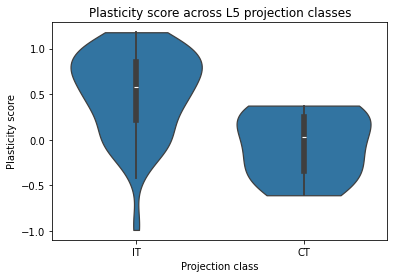

Kruskal–Wallis H=14.10, p=1.732e-04
       pair       U         p  cliffs_delta      q_BH
0  IT vs CT  1067.0  0.000176      0.686957  0.000176


In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import itertools
import numpy as np
import pandas as pd

# 2) Violin/box plot
df = adata_l5c.obs[["proj_class","plasticity_score"]].dropna()
plt.figure(figsize=(6,4))
sns.violinplot(data=df, x="proj_class", y="plasticity_score", inner="box", cut=0)
plt.title("Plasticity score across L5 projection classes")
plt.xlabel("Projection class"); plt.ylabel("Plasticity score")
plt.show()

# 3) Kruskal–Wallis (nonparametric ANOVA)
groups = [df.loc[df.proj_class==g, "plasticity_score"].values for g in ["IT","PT","CT"] if (df.proj_class==g).any()]
H, p = kruskal(*groups)
print(f"Kruskal–Wallis H={H:.2f}, p={p:.3e}")

# 4) Pairwise Wilcoxon rank-sum (Mann–Whitney) with Benjamini–Hochberg FDR
from scipy.stats import mannwhitneyu

pairs = list(itertools.combinations(["IT","PT","CT"], 2))
results = []
for a,b in pairs:
    xa = df.loc[df.proj_class==a, "plasticity_score"].values
    xb = df.loc[df.proj_class==b, "plasticity_score"].values
    if len(xa)>0 and len(xb)>0:
        stat,pv = mannwhitneyu(xa, xb, alternative="two-sided")
        # Cliff's delta effect size
        m = (xa[:,None] > xb[None,:]).mean() - (xa[:,None] < xb[None,:]).mean()
        results.append({"pair": f"{a} vs {b}", "U": stat, "p": pv, "cliffs_delta": m})

res = pd.DataFrame(results)
# BH-FDR
res = res.sort_values("p").reset_index(drop=True)
m = len(res)
res["q_BH"] = res["p"] * (m / (np.arange(m)+1))
res["q_BH"] = res["q_BH"].clip(upper=1)
print(res)


In [21]:
import statsmodels.api as sm

X = pd.DataFrame({
    "is_PT": (adata_l5c.obs["proj_class"]=="PT").astype(int),
    "is_CT": (adata_l5c.obs["proj_class"]=="CT").astype(int),
    "batch": pd.Categorical(adata_l5c.obs.get("Sequencing batch", "unknown")).codes,
    "genes_detected": pd.to_numeric(adata_l5c.obs.get("Number of genes detected"), errors="coerce")
}).fillna(0)

y = adata_l5c.obs["plasticity_score"].values
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary().tables[1])


                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.0231      0.126      0.184      0.855      -0.226       0.272
is_PT           5.289e-14   7.73e-14      0.684      0.495      -1e-13    2.06e-13
is_CT             -0.1793      0.121     -1.485      0.140      -0.418       0.060
batch             -0.0350      0.011     -3.223      0.002      -0.056      -0.013
genes_detected  5.281e-05   8.91e-06      5.929      0.000    3.52e-05    7.04e-05
